# Inspection points: Burleigh lights and drains

Two inspection plans for Burleigh Heads and Miami on the Gold Coast, made in Plotlay from open data, and read back here from the files Plotlay exported:

1. **Lights**: the City of Gold Coast's lights and poles, street lamps from OpenStreetMap that the council register does not hold, and stretches of road more than 80 m from any light on record. Then a **simulated** night patrol along nine streets, each tap matched to the light ahead.
2. **Stormwater pits**: every inlet pit and outlet, a **simulated** silt survey of 600 pits, a cleaning priority from silt and the length of pipe draining through each pit, and a cleaning run of the top 40.

The patrol and the silt survey are made up to show the workflow. Condition ratings and scores are prioritisation aids, not engineering assessments. Costs are indicative. Positions are as accurate as their sources: the council gives an accuracy class for many of its assets, OpenStreetMap gives none.

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

nums = json.load(open('../data/numbers.json'))
lights = pd.read_csv('../data/lights.csv')
pits = pd.read_csv('../data/pits.csv')
print(len(lights), 'points in the lights plan;', len(pits), 'in the pits plan')

1219 points in the lights plan; 2389 in the pits plan


## Where the lighting points came from

Each point keeps where it came from (`source`) and in words why it is there (`how`). `file` is the council register (lights and poles), `OSM` a street lamp from OpenStreetMap more than 10 m from any council light, `dark stretch` the middle of a stretch of road with no light on record for over 80 m: a place to look, not a light.

In [2]:
print(lights.groupby('source').size().rename('points').to_frame())
lights.groupby(['source', 'kind']).size().rename('points').reset_index().sort_values(['source', 'points'], ascending=[True, False])

              points
source              
OSM              174
dark stretch     294
file             751


,source,kind,points
0,OSM,Street light,174
1,dark stretch,Road segment,294
6,file,Light pole or post,347
7,file,Path or park light,229
4,file,Floodlight or sports light,117
8,file,Street light,33
3,file,Car park light,13
2,file,Bollard light,7
5,file,Internal light fitting,5


In [3]:
lights[['source', 'how']].drop_duplicates('source')

,source,how
0,file,City of Gold Coast lights: 000000006000000865
751,OSM,OSM highway=street_lamp node 5960447709
925,dark stretch,1815 m of Burleigh Street more than 80 m from ...


## Who owns them

The register names an owner for most assets. Most Queensland road lighting belongs to the electricity network (Energex), so the council register holds mostly its own park, path and car park lights; OpenStreetMap lamps have no owner stated. A fault list by owner sends each fault to the party that fixes it.

In [4]:
lights[lights.source == 'file'].groupby('owner_group').size().sort_values(ascending=False)

owner_group
Council                          662
State roads authority             54
Electricity network (utility)     23
Private                           12
dtype: int64

## Positional accuracy

The council gives an accuracy class for many of its points (`accuracy`), with an indicative distance in `accuracy_m`. OpenStreetMap lamps and the dark stretches have none: they are where a mapper or a road line puts them.

In [5]:
lights.groupby(['source', lights.accuracy.fillna('not stated')]).size().rename('points').to_frame()

points
source       accuracy                                                  
OSM          As mapped in OpenStreetMap (mapped by volunteer...     174
dark stretch The middle of the stretch                              294
file         Position as the source records it; accuracy not...     135
             The source's positional accuracy class B                 1
             The source's positional accuracy class C                 6
             The source's positional accuracy class D               335
             The source's positional accuracy class E               274

## Expected positions and dark stretches

Along the 88.6 km of OpenStreetMap roads in the area, Plotlay put an expected position every 60 m where no light is on record (`expected_lights.csv`, flagged "expected, not mapped": a check list, not points to visit) and found the stretches of road over 80 m from any light. This is a check on the record, not a lighting design or a lux calculation.

In [6]:
exp = pd.read_csv('../data/expected_lights.csv')
r = nums['roads']
print(f"{len(exp):,} expected positions; {r['dark_stretches_over_80m']} dark stretches, {r['dark_km']} km of {r['km']} km ({r['dark_share']}%)")
exp.head(3)

1,377 expected positions; 294 dark stretches, 59.6 km of 88.6 km (67%)


,n,lat,lng,why
0,1,-28.085238,153.448656,"Expected, not mapped: one light every 60 m alo..."
1,2,-28.084749,153.448393,"Expected, not mapped: one light every 60 m alo..."
2,3,-28.084236,153.448198,"Expected, not mapped: one light every 60 m alo..."


## The simulated night patrol

21 faults were planted on lights along nine streets, then a drive was simulated past them with GPS noise, and a tap made near each planted light. Plotlay matched each tap to the nearest light within 35 m, preferring one ahead of or beside the direction of travel and one not tapped already, and flagged a match to check when it was over 20 m away or had a close second. Here each match is compared with the light the fault was planted on.

In [7]:
taps = pd.read_csv('../data/patrol_taps.csv')
print(taps.right.value_counts().to_dict(), '| flagged to check:', (taps.match_status == 'check').sum())
taps[['fault', 'matched_to', 'distance_m', 'ahead', 'match_status', 'right']]

{'yes': 19, 'no': 2} | flagged to check: 5


,fault,matched_to,distance_m,ahead,match_status,right
0,flickering,Street light (OSM 12550733793),15.5,yes,ok,yes
1,out,Street light (OSM 12550733791),12.3,yes,ok,yes
2,flickering,Street light (OSM 12550733783),24.8,yes,check,yes
3,out,Street light (OSM 12550733781),17.3,yes,ok,yes
4,out,Street light (OSM 10211462649),9.8,yes,ok,yes
5,flickering,Street light (OSM 10211462648),10.1,no,check,yes
6,out,Street light (OSM 10211462642),11.8,yes,ok,yes
7,out,Street light (OSM 12550776312),20.7,yes,check,yes
8,flickering,Street light (OSM 10211462621),12.9,yes,ok,yes
9,flickering,Street light (OSM 10213697829),8.8,yes,ok,yes


In [8]:
p = nums['patrol']
assert (taps.right == 'yes').sum() == p['matched_right']
assert (taps.match_status == 'check').sum() == p['flagged_check']
wrong = taps[taps.right == 'no']
print('wrong matches:', len(wrong), '| of them flagged to check:', (wrong.match_status == 'check').sum())

wrong matches:

 2 | of them flagged to check: 1


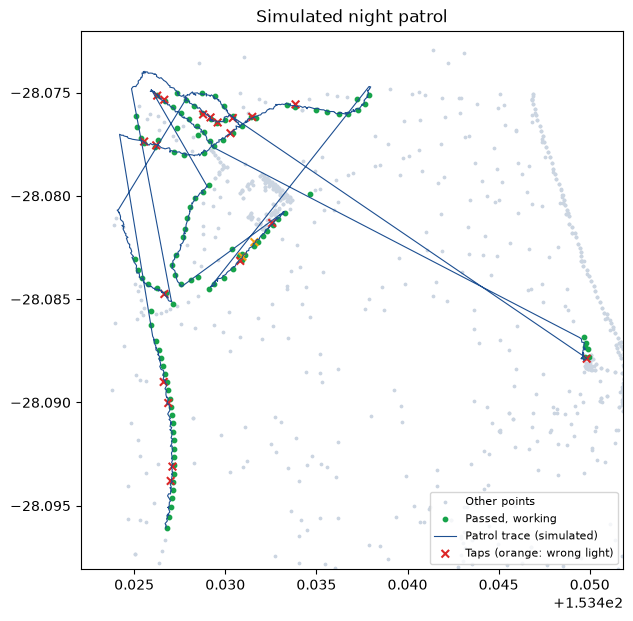

In [9]:
tr = pd.read_csv('../data/patrol_trace.csv')
fig, ax = plt.subplots(figsize=(7, 7))
done = lights[lights.status == 'Done']
ax.scatter(lights.lng, lights.lat, s=3, c='#cbd5e1', label='Other points')
ax.scatter(done.lng, done.lat, s=10, c='#16a34a', label='Passed, working')
ax.plot(tr.lng, tr.lat, lw=0.8, c='#1d4f91', label='Patrol trace (simulated)')
ax.scatter(taps.lng, taps.lat, s=30, c=np.where(taps.right == 'yes', '#dc2626', '#f59e0b'), marker='x', label='Taps (orange: wrong light)')
ax.set_xlim(tr.lng.min() - 0.002, tr.lng.max() + 0.002); ax.set_ylim(tr.lat.min() - 0.002, tr.lat.max() + 0.002)
ax.set_aspect(1 / np.cos(np.radians(-28.09))); ax.legend(loc='lower right', fontsize=8); ax.set_title('Simulated night patrol')
plt.show()

## Stormwater: the cleaning priority, worked again

Each surveyed pit scores the weighted mean of two drivers, each 0 to 100:

- **Silt and debris** last seen, as a share of the pit's depth (weight 50).
- **Upstream catchment**: the length of pipe draining through the pit, from a trace of the council's pipe network, as a percentile over every pit with a value (weight 30). No open flood-prone area layer covers this area, so the flood weight (20) is not used.

Pits nobody has looked into yet are left unscored, so they never top a cleaning run on a guess.

In [10]:
cp = pd.read_csv('../data/cleaning_priority.csv')
c = cp.catchment_m.dropna().sort_values().to_numpy()
pct = cp.catchment_m.map(lambda v: np.nan if pd.isna(v) else round(np.searchsorted(c, v, side='right') / len(c) * 100, 1))
w_s, w_c = 50, 30
num = cp.silt_pct * w_s + pct.fillna(0) * w_c
den = w_s + np.where(pct.notna(), w_c, 0)
mine = (num / den).where(cp.silt_pct.notna()).round(1)
diff = (mine - cp.score).abs()
print('scored:', cp.score.notna().sum(), '| largest difference from Plotlay:', diff.max())
cp.head(10)[['rank', 'name', 'score', 'silt_pct', 'catchment_m', 'needs', 'in_cleaning_run']]

scored: 600 | largest difference from Plotlay: 0.10000000000000142


,rank,name,score,silt_pct,catchment_m,needs,in_cleaning_run
0,1,Side entry pit 000000004000046393,84.2,75.0,1325.0,Cleaning and repair,yes
1,2,Side entry pit 000000004000046975,84.0,75.0,860.0,Cleaning,yes
2,3,Side entry pit 000000004000175100,77.0,75.0,11.0,Cleaning,yes
3,4,Side entry pit 000000004000168889,75.8,75.0,7.0,Cleaning and repair,yes
4,5,Side entry pit 000000004000178648,75.3,75.0,6.0,Cleaning,yes
5,6,Side entry pit 000000004000140486,72.8,75.0,0.0,Cleaning,yes
6,7,Side entry pit 000000004000164043,72.8,75.0,0.0,Cleaning,yes
7,8,Side entry pit 000000004000165297,72.8,75.0,0.0,Cleaning,yes
8,9,Side entry pit 000000004000169941,72.8,75.0,0.0,Cleaning,yes
9,10,Side entry pit 000000004000184865,72.8,75.0,0.0,Cleaning,yes


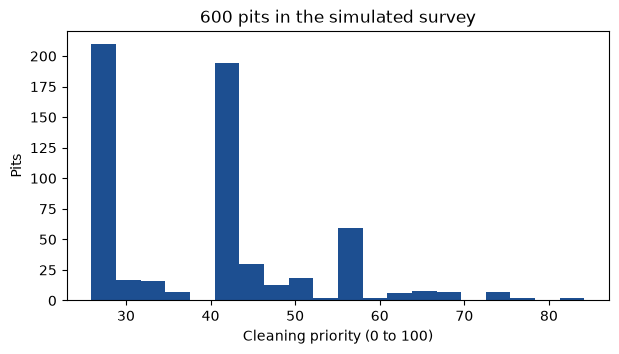

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
cp.score.dropna().plot.hist(bins=20, ax=ax, color='#1d4f91')
ax.set_xlabel('Cleaning priority (0 to 100)'); ax.set_ylabel('Pits'); ax.set_title('600 pits in the simulated survey')
plt.show()

## Repairs, priced (indicative)

Faults and pits needing work became repairs, each priced from a Plotlay price book line (labour hours at a trade rate plus materials, with a low and high range). Indicative only: real costs depend on access, traffic management and the market.

In [12]:
rep = pd.read_csv('../data/repairs.csv')
t = rep.groupby(['plan', 'code']).agg(repairs=('ref', 'count'), amount_aud=('amount_aud', 'sum')).round(0)
print(t)
print('total A$', round(rep.amount_aud.sum()), '| range A$', round(rep.low_aud.sum()), 'to', round(rep.high_aud.sum()))

                                           repairs  amount_aud
plan                         code                             
Burleigh lights              lt.lamp            19      5493.0
                             lt.pe_cell          1       156.0
                             tr.prune            1       500.0
Burleigh pits before the wet sw.grate           26     10819.0
                             sw.pit_clean       93     13950.0
total A$ 30918 | range A$ 23899 to 45982


## The sample site (made up)

`data/site/site-lighting.dxf` is a made-up community centre drawn as a lighting consultant would: each fitting a named block on its own layer. Plotlay read the blocks into inspection points by their names (car park poles, wall packs, bollards, a floodlight, emergency lights and exit signs), and a **simulated** six-monthly emergency lighting test was recorded on each emergency fitting. The test record follows AS/NZS 2293.2 as a reference only: the standard and the building's maintenance contract say what a test must include.

In [13]:
site = pd.read_csv('../data/site/points.csv')
em = pd.read_csv('../data/site/emergency_tests.csv')
print(site.kind.value_counts().to_dict())
em

{'Emergency light': 12, 'Car park light': 8, 'Wall pack or building-mounted light': 8, 'Bollard light': 5, 'Exit sign': 4, 'Floodlight or sports light': 1}


,id,name,kind,level,tested,on_mains,lasted_on_battery,minutes_if_failed,result,next_due,state
0,EL-001,Emergency light EM_LIGHT 1,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
1,EL-002,Emergency light EM_LIGHT 2,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
2,EL-003,Emergency light EM_LIGHT 3,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
3,EL-004,Emergency light EM_LIGHT 4,Emergency light,NaN,2026-11-20,yes,no,40.0,Fail,2027-05-20,Next due 2027-05-20
4,EL-005,Emergency light EM_LIGHT 5,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
5,EL-006,Emergency light EM_LIGHT 6,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
6,EL-007,Emergency light EM_LIGHT 7,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
7,EL-008,Emergency light EM_LIGHT 8,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
8,EL-009,Emergency light EM_LIGHT 9,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
9,EL-010,Emergency light EM_LIGHT 10,Emergency light,NaN,2026-11-20,yes,yes,NaN,Pass,2027-05-20,Next due 2027-05-20
